In [1]:
import tensorflow as tf
from pathlib import Path
import keras
from keras.optimizers import Adam
from keras import layers
import json
import cv2
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import shutil
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

In [2]:


dataset_path = Path("archive")

classes=["angry", "happy", "neutral", "sad", "surprise"]

IMG_SIZE = (48, 48)
BATCH_SIZE = 64

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "train",
    validation_split=0.2,
    subset='training',
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    class_names=classes
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "train",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    class_names=classes
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    shuffle=False,
    class_names=classes
)

print("\nClass names:", train_ds.class_names)

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.numpy().min(), images.numpy().max())

Found 24176 files belonging to 5 classes.
Using 19341 files for training.
Found 24176 files belonging to 5 classes.
Using 4835 files for validation.
Found 6043 files belonging to 5 classes.

Class names: ['angry', 'happy', 'neutral', 'sad', 'surprise']
Image batch shape: (64, 48, 48, 1)
Label batch shape: (64,)
Pixel range: 0.0 255.0


In [3]:
train_ds=train_ds.map(
    lambda images,labels:(images/255,labels)
)

test_ds=test_ds.map(
    lambda images,labels:(images/255,labels)
)
val_ds=val_ds.map(
    lambda images,labels:(images/255,labels)
)

In [4]:
from sklearn.utils.class_weight import compute_class_weight

y_train = np.concatenate([
    labels.numpy() for _, labels in train_ds
])

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=y_train
)

weights = np.sqrt(weights)
weights = weights / weights.mean()

class_weight = {
    i: float(weights[i]) for i in range(len(classes))
}

class_weight[classes.index("angry")] *= 1.15

print("وزن‌های جدید:", class_weight)


print("وزن کلاس‌ها:", class_weight)

وزن‌های جدید: {0: 1.2238702945268918, 1: 0.7950965963559921, 2: 0.9575017090719083, 3: 0.9789655134946599, 4: 1.2042011423584034}
وزن کلاس‌ها: {0: 1.2238702945268918, 1: 0.7950965963559921, 2: 0.9575017090719083, 3: 0.9789655134946599, 4: 1.2042011423584034}


In [5]:
images, labels = next(iter(train_ds))

print("Pixel min:", images.numpy().min())
print("Pixel max:", images.numpy().max())
print("Image shape:", images.shape)

Pixel min: 0.0
Pixel max: 1.0
Image shape: (64, 48, 48, 1)


In [6]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
])

In [7]:
model=keras.Sequential([

    layers.Input(shape=(48,48,1)),
    data_augmentation,
    layers.Conv2D(32,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.20),

    layers.Conv2D(64,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.25),

    layers.Conv2D(128,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.30),

    layers.Conv2D(256,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(256,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.35),



    layers.GlobalAveragePooling2D(),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.40),

    layers.Dense(5,activation='softmax')
])

In [8]:
model.compile(optimizer=Adam(learning_rate=0.0005),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [9]:

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_fer_model.keras",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_delta=0.002,
        cooldown=1,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=9,
        min_delta=0.001,
        restore_best_weights=True,
        verbose=1
    )
]




history=model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks,
    class_weight=class_weight
)

Epoch 1/50
302/303 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.2490 - loss: 1.7262
Epoch 1: val_loss improved from None to 1.83081, saving model to best_fer_model.keras

Epoch 1: finished saving model to best_fer_model.keras
303/303 ━━━━━━━━━━━━━━━━━━━━ 40s 122ms/step - accuracy: 0.2714 - loss: 1.6053 - val_accuracy: 0.2697 - val_loss: 1.8308 - learning_rate: 5.0000e-04
Epoch 2/50
302/303 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.3547 - loss: 1.4715
Epoch 2: val_loss improved from 1.83081 to 1.32061, saving model to best_fer_model.keras

Epoch 2: finished saving model to best_fer_model.keras
303/303 ━━━━━━━━━━━━━━━━━━━━ 41s 122ms/step - accuracy: 0.3771 - loss: 1.4333 - val_accuracy: 0.4319 - val_loss: 1.3206 - learning_rate: 5.0000e-04
Epoch 3/50
302/303 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.4453 - loss: 1.3216
Epoch 3: val_loss improved from 1.32061 to 1.13942, saving model to best_fer_model.keras

Epoch 3: finished saving model to best_fer_model.keras
303/303 

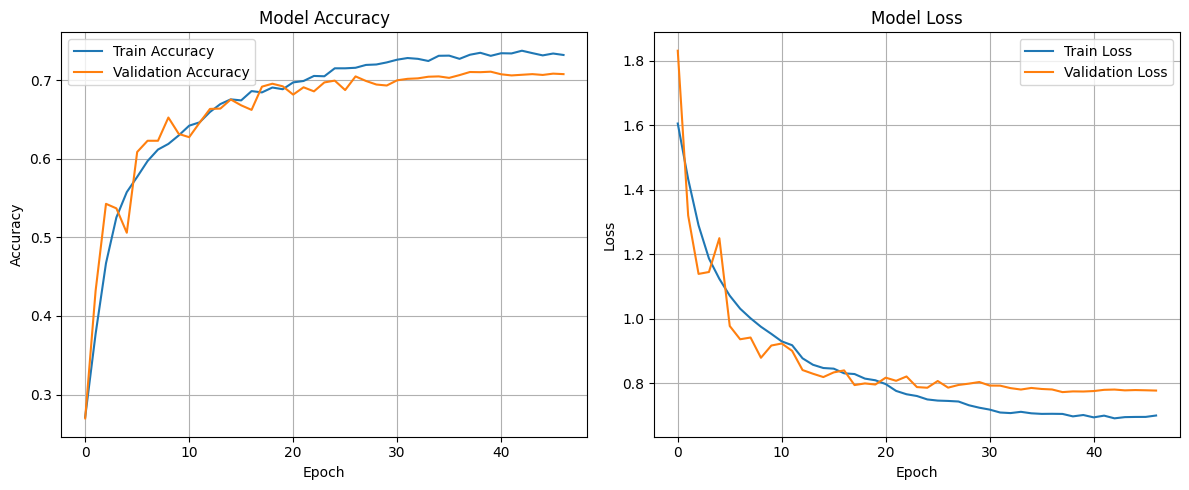

In [10]:



plt.figure(figsize=(12, 5))

# نمودار دقت
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# نمودار خطا
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

In [11]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Test Loss: {test_loss:.4f}")

95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7203 - loss: 0.7541
Test Accuracy: 72.03%
Test Loss: 0.7541


In [12]:


y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.concatenate([
    np.argmax(model.predict(images, verbose=0), axis=1)
    for images, labels in test_ds
])

print(classification_report(
    y_true,
    y_pred,
    target_names=["angry", "happy", "neutral", "sad", "surprise"],
    zero_division=0
))

              precision    recall  f1-score   support

       angry       0.62      0.67      0.64       958
       happy       0.89      0.83      0.86      1774
     neutral       0.60      0.70      0.64      1233
         sad       0.65      0.53      0.58      1247
    surprise       0.80      0.86      0.83       831

    accuracy                           0.72      6043
   macro avg       0.71      0.72      0.71      6043
weighted avg       0.73      0.72      0.72      6043



In [13]:

shutil.copy("best_fer_model.keras", "model2_v2_69.keras")

'model2_v2_69.keras'

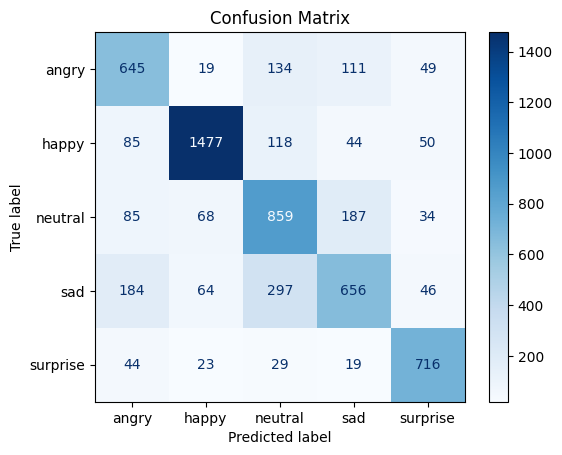

In [14]:


cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=classes)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [15]:
best_model = keras.models.load_model("best_fer_model.keras")

best_model.save("fer2_model_72_percent.keras")

print("مدل با موفقیت ذخیره شد!")

مدل با موفقیت ذخیره شد!


In [16]:


CLASSES = ["angry", "happy", "neutral", "sad", "surprise"]  # same order as training
model = keras.models.load_model("fer2_model_72_percent.keras")
cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def predict_mood(path):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = cascade.detectMultiScale(gray, 1.3, 5)
    if len(faces) > 0:
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])  # biggest face
        gray = gray[y:y + h, x:x + w]

    gray = cv2.resize(gray, (48, 48)) / 255.0
    arr = gray.reshape(1, 48, 48, 1)

    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    return {"mood": CLASSES[idx], "confidence": round(float(probs[idx]), 2)}

for name in ["happy", "sad", "neutral"]:
    result = predict_mood(f"my_photos/{name}.jpg")
    print(name, "->", json.dumps(result))

happy -> {"mood": "happy", "confidence": 0.93}
sad -> {"mood": "sad", "confidence": 0.79}
neutral -> {"mood": "neutral", "confidence": 0.85}
